In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [5]:
df = pd.read_csv('Diabetes_prediction.csv')

In [6]:
df.head(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [7]:
print(f'Idade min: {df['Age'].min()}')
print(f'Idade max: {df['Age'].max()}')

Idade min: -0.979803578151646
Idade max: 90.5737824472806


In [8]:
print(df['Insulin'].min())
print(df['Insulin'].max())

-165.3100326101158
317.701851723486


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               1000 non-null   int64  
 1   Glucose                   1000 non-null   float64
 2   BloodPressure             1000 non-null   float64
 3   SkinThickness             1000 non-null   float64
 4   Insulin                   1000 non-null   float64
 5   BMI                       1000 non-null   float64
 6   DiabetesPedigreeFunction  1000 non-null   float64
 7   Age                       1000 non-null   float64
 8   Diagnosis                 1000 non-null   int64  
dtypes: float64(7), int64(2)
memory usage: 70.4 KB


In [10]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,1.771000,99.440607,72.179837,23.278316,84.582679,25.433600,0.449383,43.281798,0.30600
std,1.354398,19.470730,13.882017,1.173807,74.872733,3.690223,0.199334,14.465398,0.46106
min,0.000000,30.571402,31.401487,19.369987,-165.310033,13.548818,0.100037,-0.979804,0.00000
25%,1.000000,86.145927,62.795447,22.501591,35.076535,23.022715,0.283376,33.518451,0.00000
50%,2.000000,99.458362,71.909588,23.275225,84.442232,25.455649,0.448219,43.634273,0.00000
75%,3.000000,113.264556,82.082660,24.052022,134.267842,27.972184,0.619158,53.098446,1.00000
max,8.000000,161.238939,110.723715,26.917654,317.701852,36.324598,0.799654,90.573782,1.00000


<Axes: >

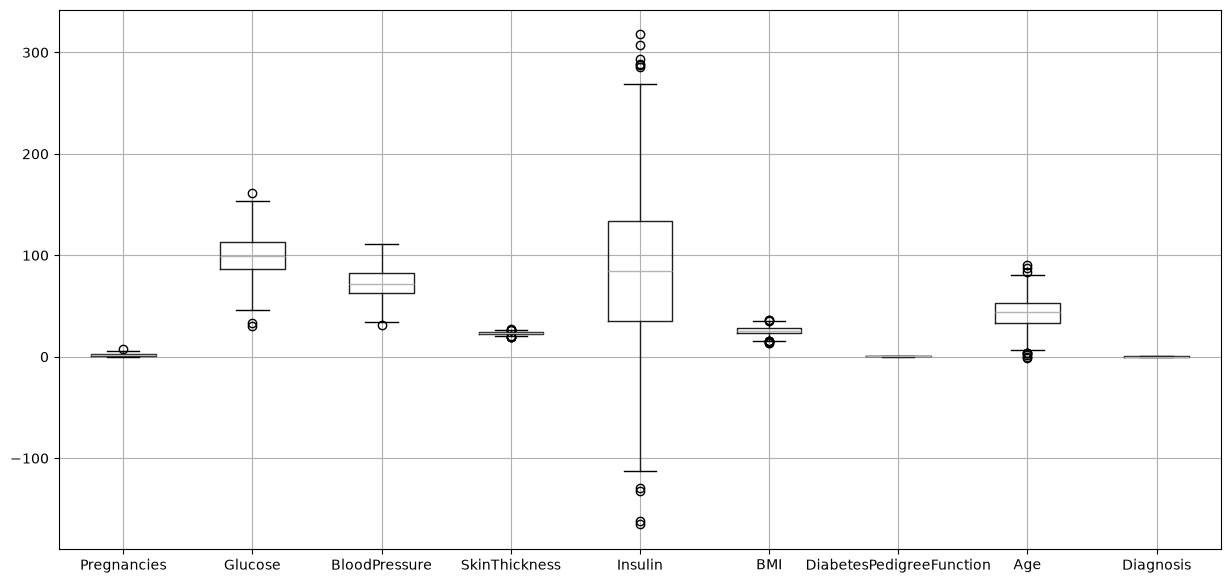

In [11]:

df.boxplot(figsize=(15, 7))

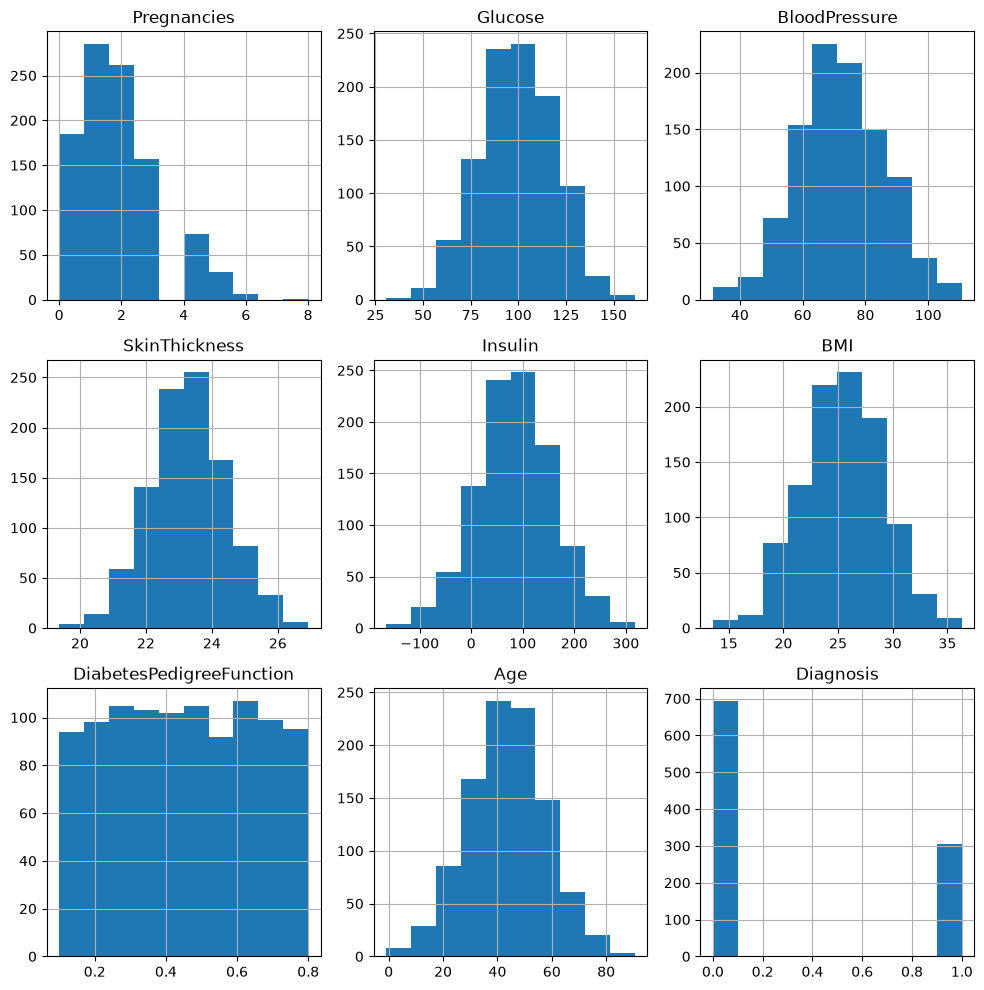

In [12]:
import matplotlib.pyplot as plt

# Plot histograms for all variables
df.hist(figsize=(10, 10))
plt.tight_layout()
plt.show()


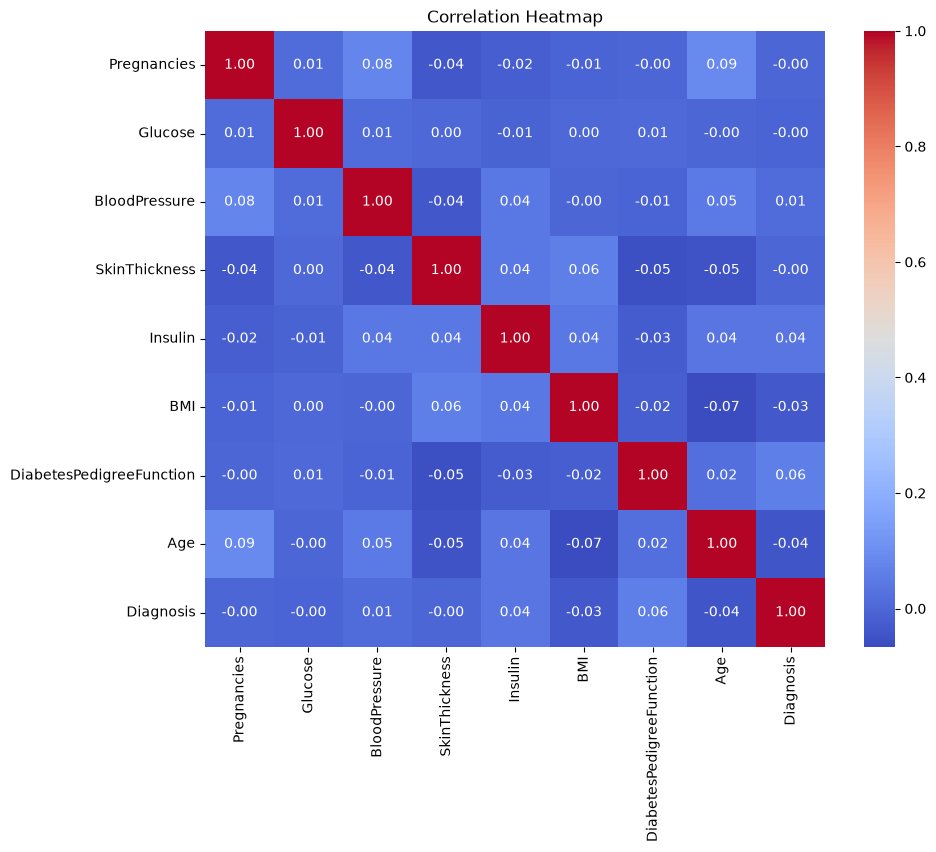

In [13]:
import seaborn as sns
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


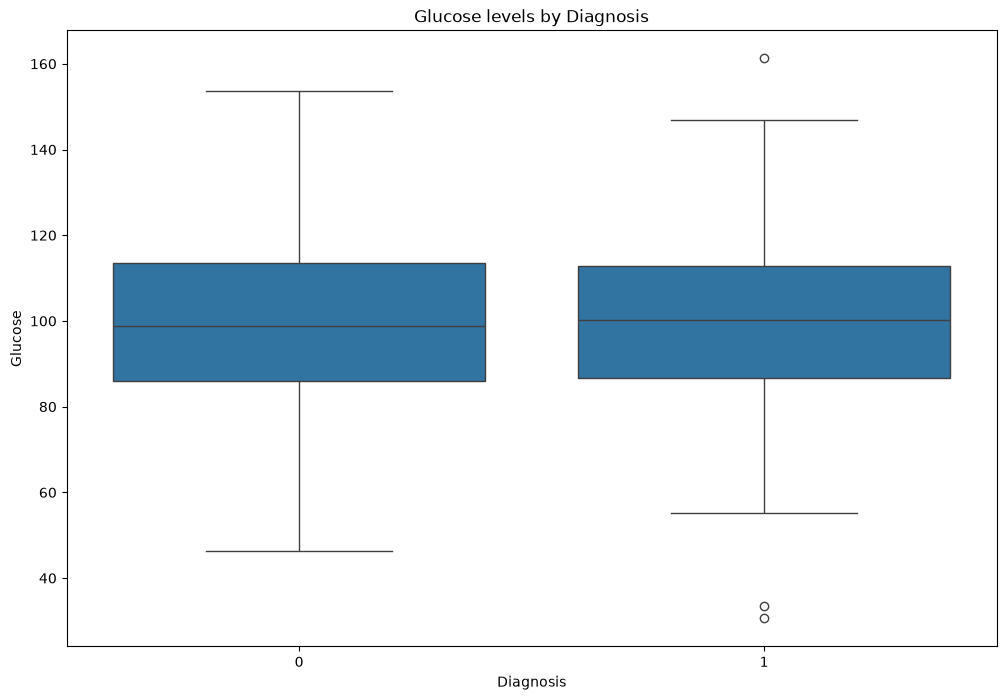

In [14]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='Diagnosis', y='Glucose', data=df)
plt.title('Glucose levels by Diagnosis')
plt.show()


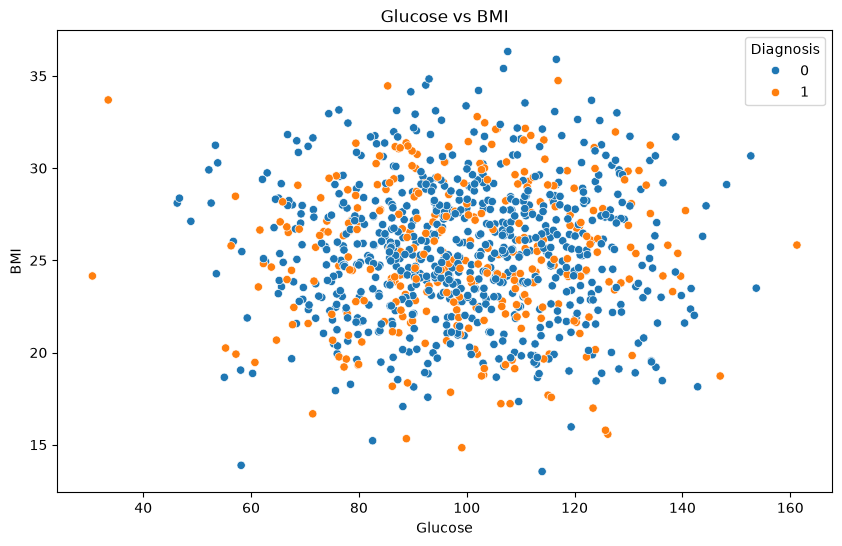

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Glucose', y='BMI', hue='Diagnosis', data=df)
plt.title('Glucose vs BMI')
plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.show()


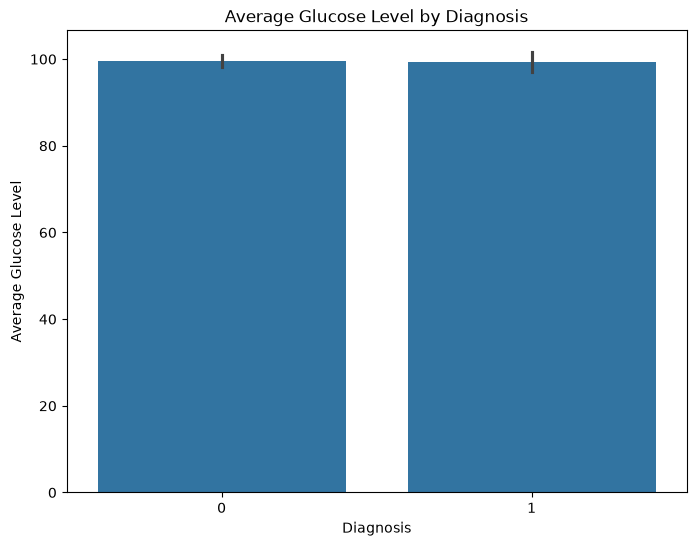

In [16]:
plt.figure(figsize=(8, 6))
sns.barplot(x='Diagnosis', y='Glucose', data=df)
plt.title('Average Glucose Level by Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Average Glucose Level')
plt.show()


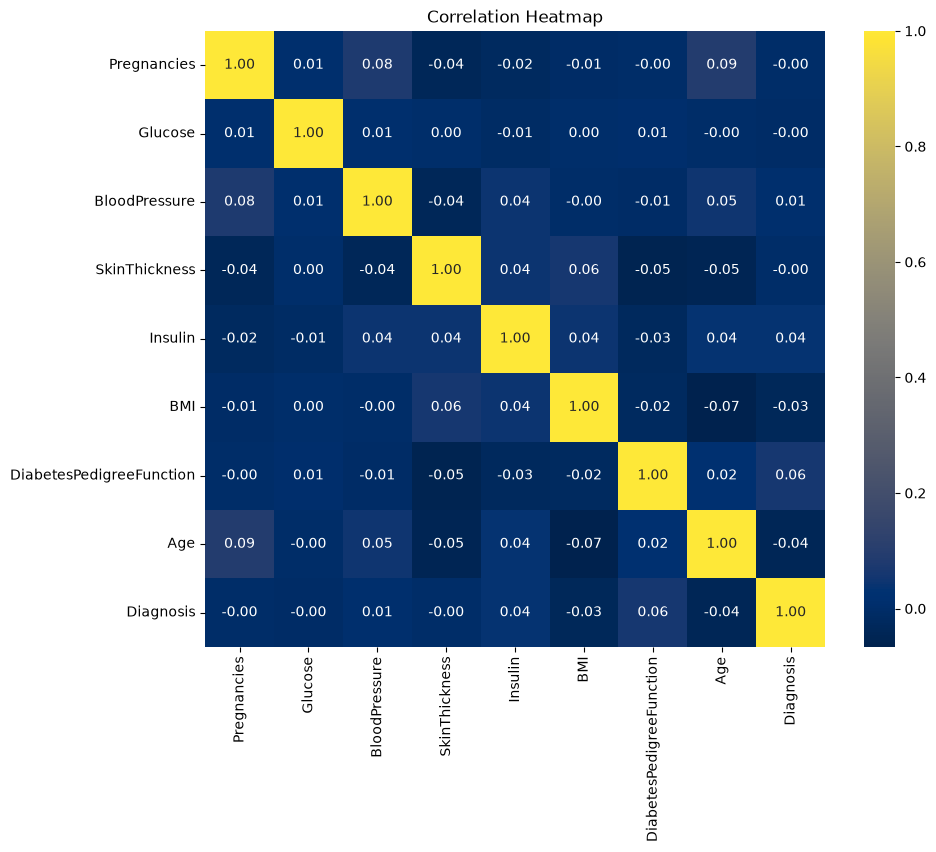

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='cividis', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


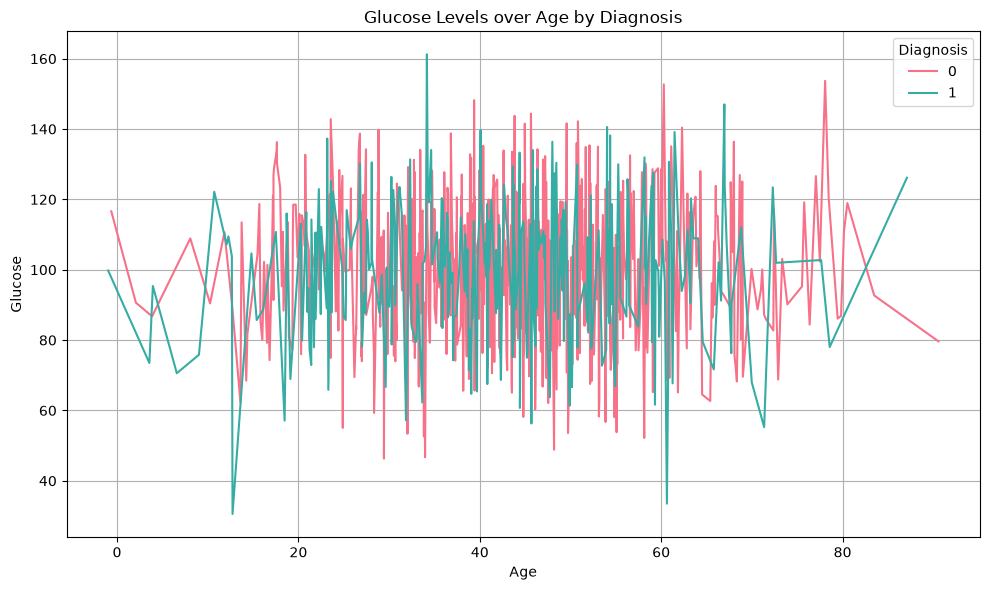

In [18]:
# Assuming you want to plot Glucose levels over Age for each Diagnosis category

plt.figure(figsize=(10, 6))
sns.lineplot(x='Age', y='Glucose', hue='Diagnosis', data=df, palette='husl')
plt.title('Glucose Levels over Age by Diagnosis')
plt.xlabel('Age')
plt.ylabel('Glucose')
plt.legend(title='Diagnosis')
plt.grid(True)
plt.tight_layout()
plt.show()


In [19]:
df.boxplot(figsize=(15, 7))

<Axes: >

In [20]:
print("Dimensão:", df.shape)

print("\nTipos:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nDuplicados:")
print(df.duplicated().sum())

print("\nEstatísticas:")
print(df.describe().T)

Dimensão: (1000, 9)

Tipos:
Pregnancies                   int64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                         float64
Diagnosis                     int64
dtype: object

Valores ausentes:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Diagnosis                   0
dtype: int64

Duplicados:
0

Estatísticas:
                           count       mean        std         min        25%  \
Pregnancies               1000.0   1.771000   1.354398    0.000000   1.000000   
Glucose                   1000.0  99.440607  19.470730   30.571402  86.145927   
BloodPressure             1000.0  72.179837  13.882017   31

In [21]:
colunas = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "Age"
]

for coluna in colunas:
    print(
        coluna,
        "negativos =", (df[coluna] < 0).sum(),
        "zeros =", (df[coluna] == 0).sum(),
        "mínimo =", df[coluna].min(),
        "máximo =", df[coluna].max()
    )

Glucose negativos = 0 zeros = 0 mínimo = 30.571402161232346 máximo = 161.23893930812437
BloodPressure negativos = 0 zeros = 0 mínimo = 31.40148707615002 máximo = 110.72371460214974
SkinThickness negativos = 0 zeros = 0 mínimo = 19.369987239303853 máximo = 26.917654051162653
Insulin negativos = 127 zeros = 0 mínimo = -165.3100326101158 máximo = 317.701851723486
BMI negativos = 0 zeros = 0 mínimo = 13.548817852644664 máximo = 36.324597869685
Age negativos = 2 zeros = 0 mínimo = -0.979803578151646 máximo = 90.5737824472806


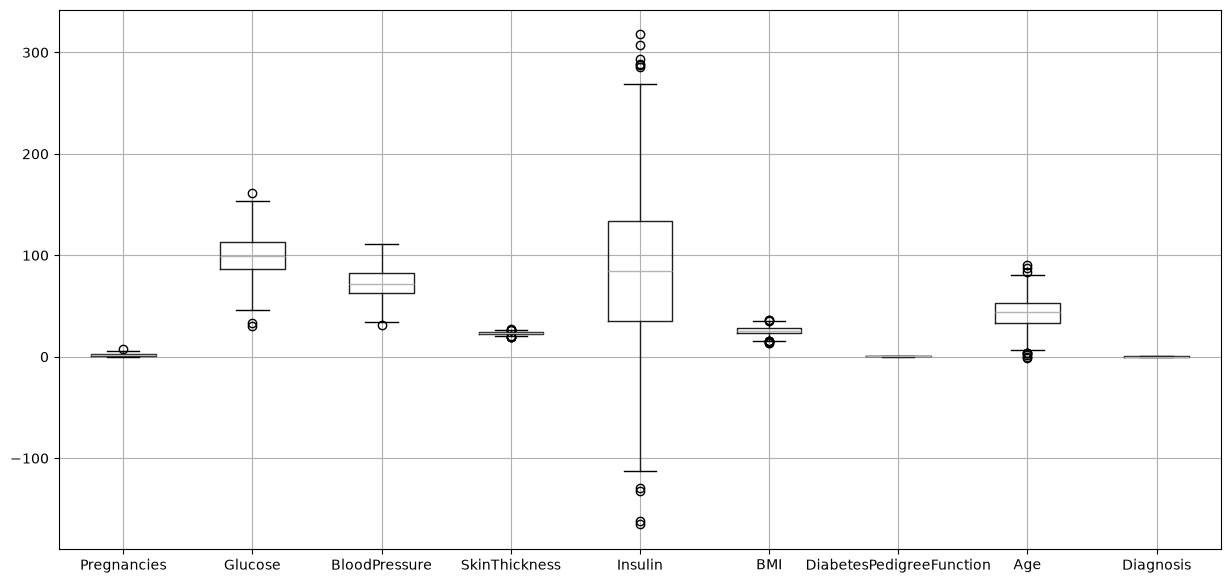

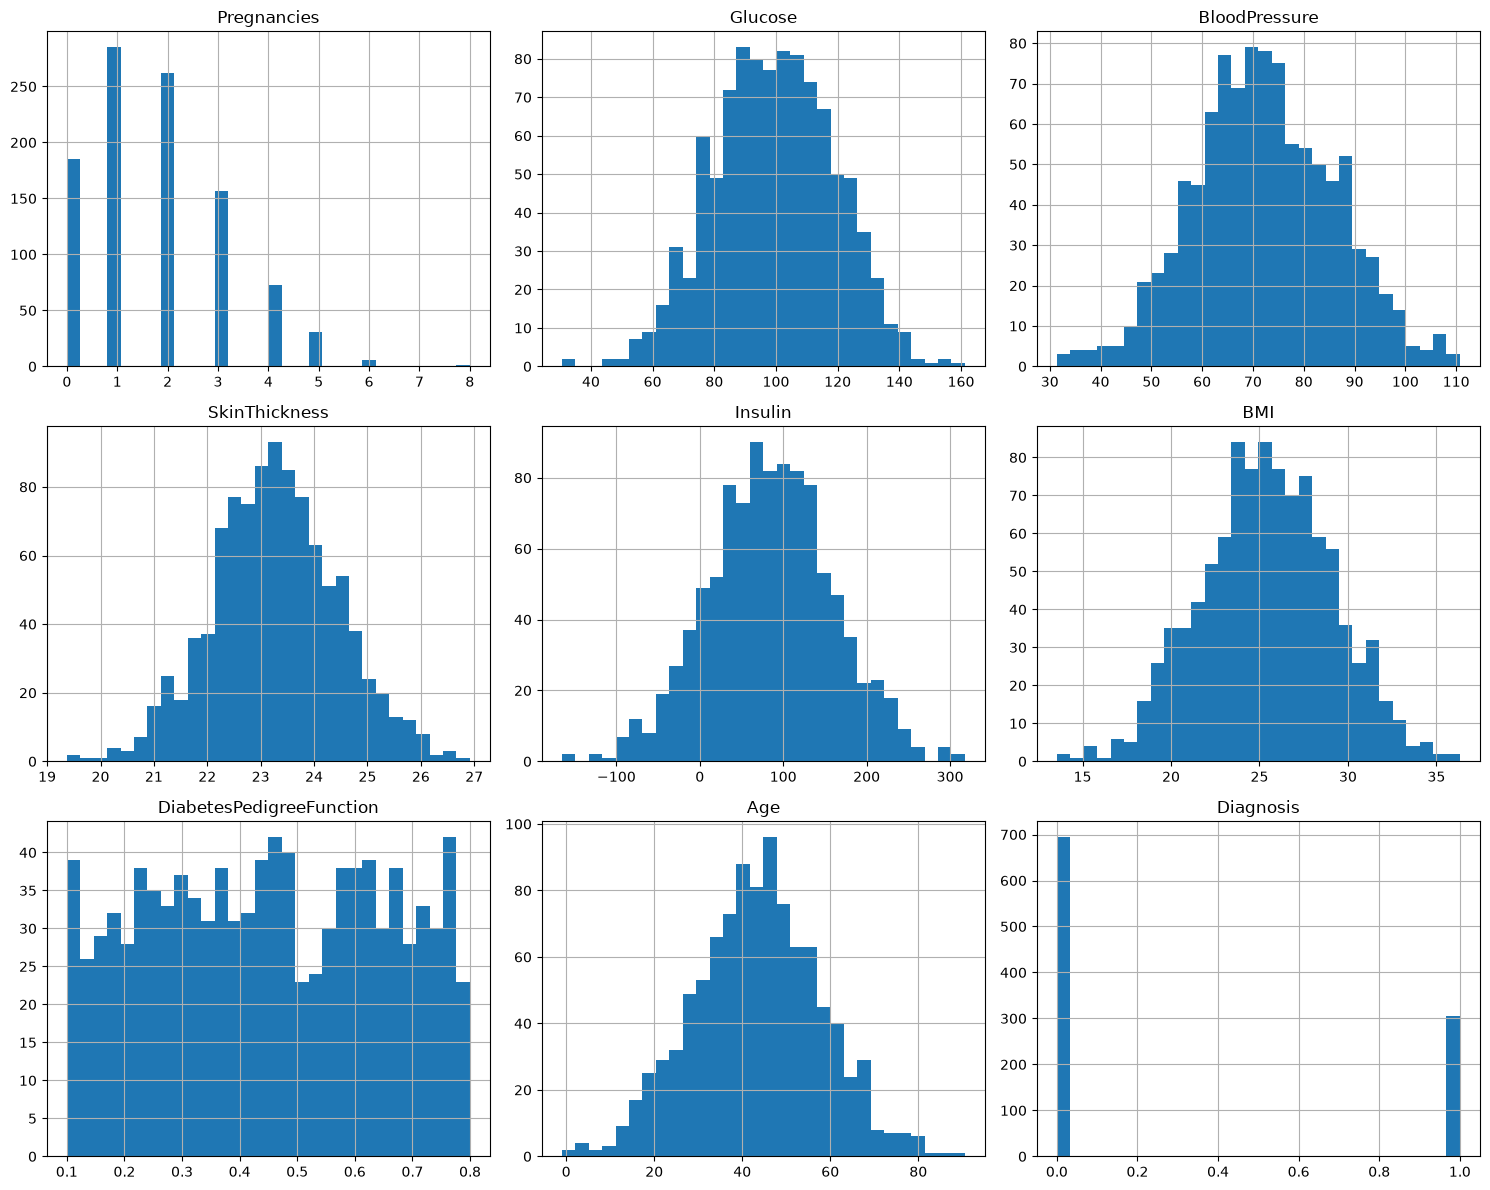

In [22]:
df.hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

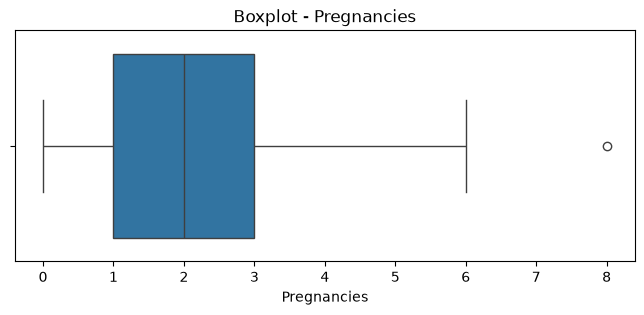

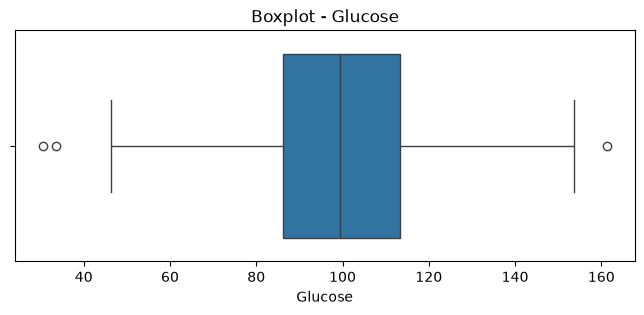

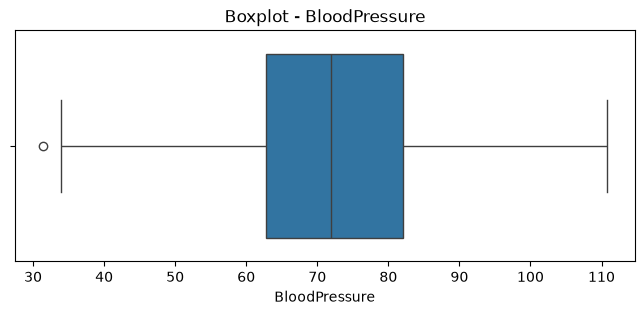

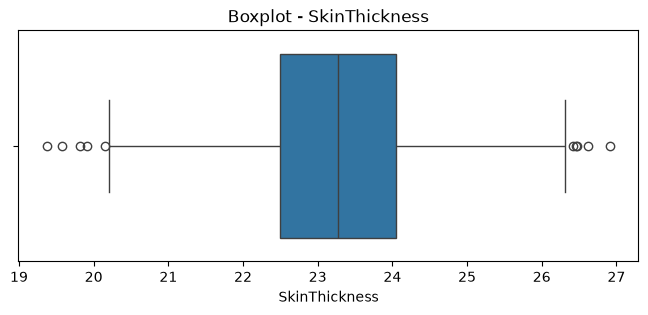

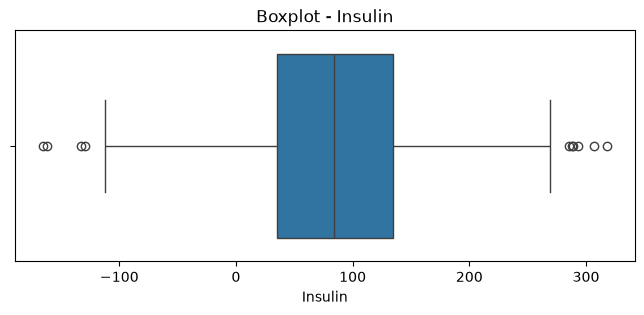

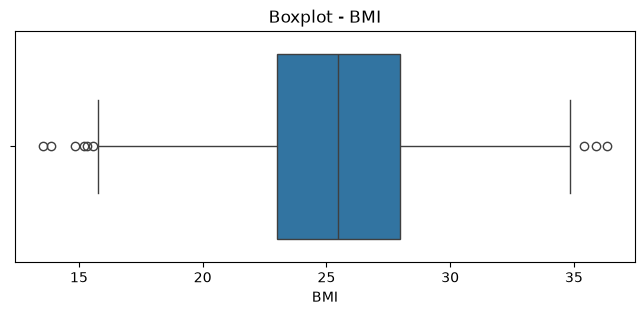

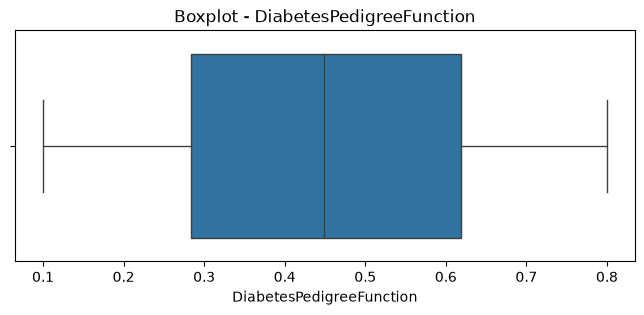

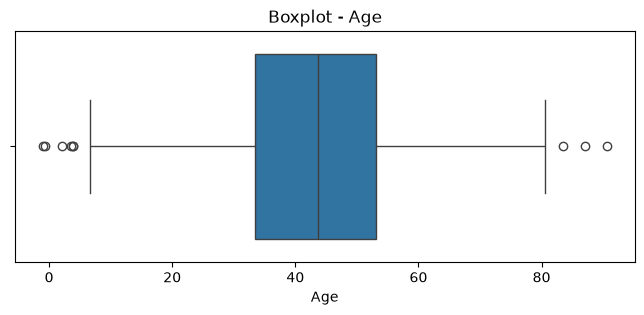

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

for coluna in df.columns[:-1]:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[coluna])
    plt.title(f"Boxplot - {coluna}")
    plt.show()

In [24]:
for coluna in df.columns[:-1]:

    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(coluna, len(outliers))

Pregnancies 1
Glucose 3
BloodPressure 1
SkinThickness 10
Insulin 10
BMI 9
DiabetesPedigreeFunction 0
Age 9


In [25]:
print(df["Diagnosis"].value_counts())

print(
    df["Diagnosis"].value_counts(normalize=True) * 100
)

Diagnosis
0    694
1    306
Name: count, dtype: int64
Diagnosis
0    69.4
1    30.6
Name: proportion, dtype: float64


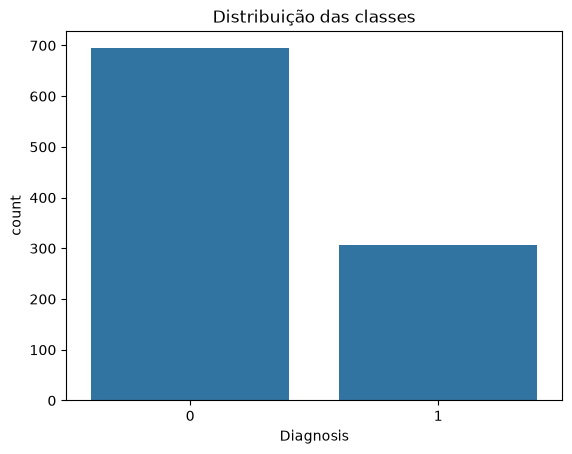

In [26]:
sns.countplot(x="Diagnosis", data=df)
plt.title("Distribuição das classes")
plt.show()

In [27]:
df.groupby("Diagnosis").mean().T

Diagnosis,0,1
Pregnancies,1.772334,1.767974
Glucose,99.504846,99.294917
BloodPressure,72.084485,72.396092
SkinThickness,23.278327,23.278291
Insulin,82.823035,88.573505
BMI,25.515244,25.248433
DiabetesPedigreeFunction,0.441372,0.467550
Age,43.711192,42.307942


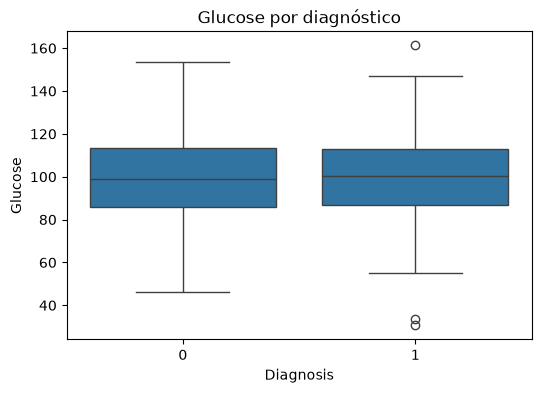

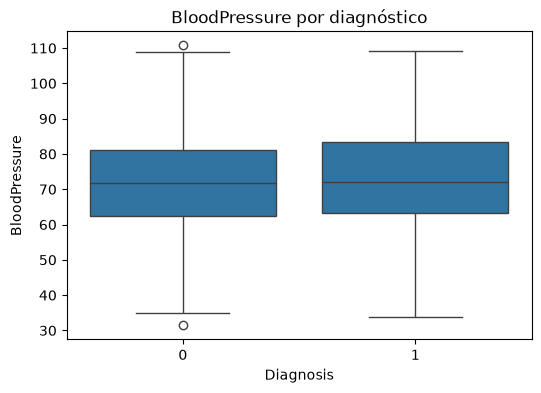

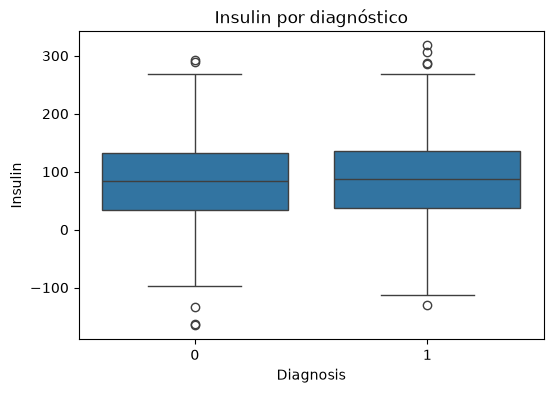

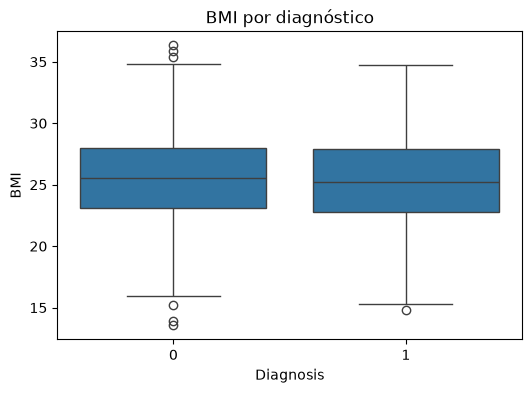

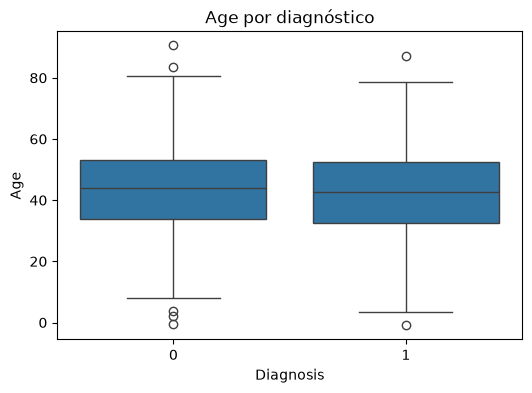

In [28]:
features = [
    "Glucose",
    "BloodPressure",
    "Insulin",
    "BMI",
    "Age"
]

for coluna in features:
    plt.figure(figsize=(6, 4))

    sns.boxplot(
        x="Diagnosis",
        y=coluna,
        data=df
    )

    plt.title(f"{coluna} por diagnóstico")
    plt.show()

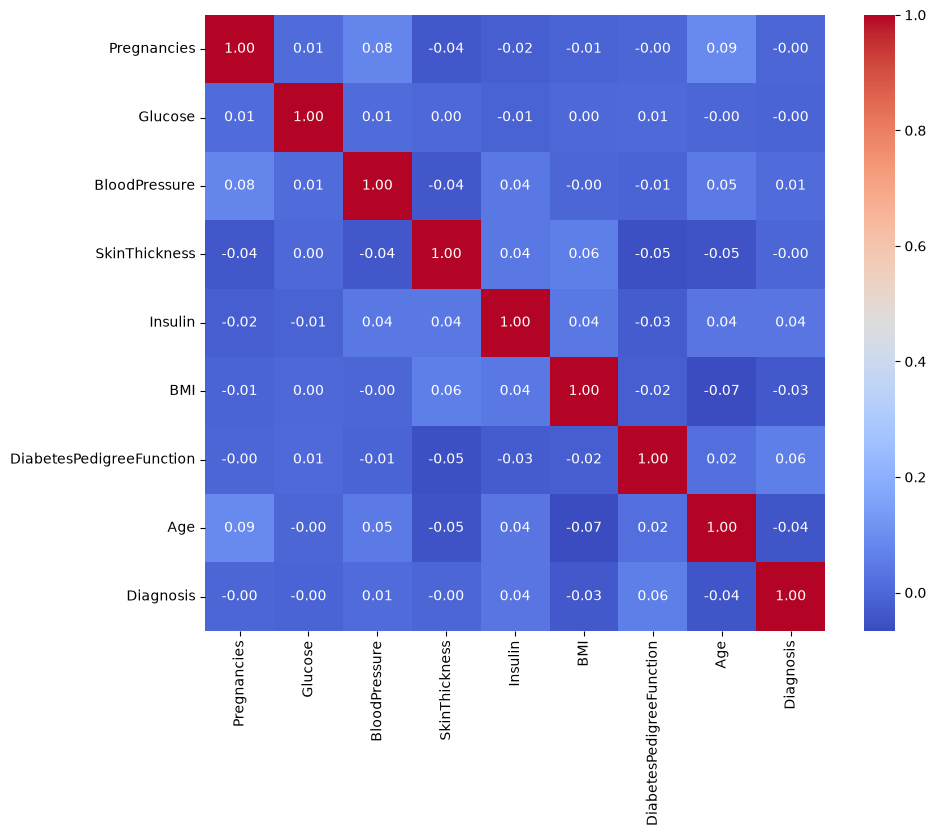

In [29]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

In [30]:
correlacao_diagnostico = (
    df.corr()["Diagnosis"]
      .sort_values(ascending=False)
)

print(correlacao_diagnostico)

Diagnosis                   1.000000
DiabetesPedigreeFunction    0.060549
Insulin                     0.035411
BloodPressure               0.010349
SkinThickness              -0.000014
Pregnancies                -0.001484
Glucose                    -0.004971
BMI                        -0.033336
Age                        -0.044726
Name: Diagnosis, dtype: float64


## Preparação dos dados para Machine Learning

Após a análise exploratória, vamos separar as variáveis preditoras
(features) da variável alvo (target), que será utilizada para o
treinamento dos modelos.



In [31]:
# Variáveis de entrada (features)
X = df.drop("Diagnosis", axis=1)

# Variável que queremos prever (target)
y = df["Diagnosis"]

In [32]:
print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

print("\nPrimeiras linhas de X:")
display(X.head())

print("\nPrimeiros valores de y:")
display(y.head())

Formato de X: (1000, 8)
Formato de y: (1000,)

Primeiras linhas de X:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789



Primeiros valores de y:


0    0
1    0
2    1
3    0
4    0
Name: Diagnosis, dtype: int64

In [33]:
print(X.shape)
print(y.shape)
print(y.value_counts())

(1000, 8)
(1000,)
Diagnosis
0    694
1    306
Name: count, dtype: int64


## 4. Separação dos Dados em Treino e Teste

Os dados serão divididos em conjuntos de treino e teste.
O conjunto de treino será utilizado para ensinar o modelo, enquanto
o conjunto de teste será utilizado para avaliar seu desempenho com
dados que não foram utilizados durante o treinamento.

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [35]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nDistribuição no treino:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nDistribuição no teste:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

X_train: (800, 8)
X_test : (200, 8)
y_train: (800,)
y_test : (200,)

Distribuição no treino:
Diagnosis
0    555
1    245
Name: count, dtype: int64
Diagnosis
0    0.69375
1    0.30625
Name: proportion, dtype: float64

Distribuição no teste:
Diagnosis
0    139
1     61
Name: count, dtype: int64
Diagnosis
0    0.695
1    0.305
Name: proportion, dtype: float64


In [36]:
X_train.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
Pregnancies,1.792500,1.375430,0.000000,8.000000
Glucose,98.755081,19.558462,30.571402,161.238939
BloodPressure,72.137607,14.129356,31.401487,110.723715
SkinThickness,23.319562,1.162323,19.580395,26.917654
Insulin,84.311302,75.105807,-165.310033,317.701852
BMI,25.386262,3.664803,13.883876,36.324598
DiabetesPedigreeFunction,0.448932,0.198922,0.100037,0.799032
Age,43.521898,14.519409,-0.633140,90.573782


In [39]:
print("Age negativo:")
print((df["Age"] < 0).sum())

print("\nInsulin negativo:")
print((df["Insulin"] < 0).sum())

Age negativo:
2

Insulin negativo:
127


In [40]:
print("Registros com Age negativo:")
display(df[df["Age"] < 0])

print("\nRegistros com Insulin negativo:")
display(df[df["Insulin"] < 0])

Registros com Age negativo:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
339,0,99.781243,90.732356,22.519621,90.315212,24.983837,0.198539,-0.979804,1
617,1,116.614197,65.168094,24.378341,77.370354,35.900092,0.453615,-0.633140,0



Registros com Insulin negativo:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
8,2,120.979399,50.617860,23.677139,-11.616854,21.032709,0.105676,42.743013,1
28,0,76.322296,60.700040,22.305300,-86.008163,28.611473,0.238183,40.298644,0
31,5,102.640418,83.572981,22.280805,-132.634517,25.475204,0.748052,60.130496,0
36,3,89.476753,90.406918,22.172357,-3.105602,26.545101,0.449196,30.011244,1
37,0,111.754633,59.816413,21.007746,-92.008634,25.523157,0.271231,42.190415,0
...,...,...,...,...,...,...,...,...,...
968,2,86.015236,59.177054,21.816176,-97.135976,22.530334,0.310459,49.370926,0
975,3,101.468690,69.114257,25.205953,-3.515836,29.142549,0.671075,29.958696,0
978,3,82.589658,73.851819,22.548939,-82.061661,23.456476,0.571801,36.359073,0
990,0,112.810672,91.694932,22.407337,-162.251127,26.228355,0.201161,52.460526,0


In [43]:
# Estatísticas da Insulin
print(df["Insulin"].describe())

print("\nInsulin negativa:")
print(df[df["Insulin"] < 0]["Insulin"].describe())

print("\nInsulin não negativa:")
print(df[df["Insulin"] >= 0]["Insulin"].describe())

count    1000.000000
mean       84.582679
std        74.872733
min      -165.310033
25%        35.076535
50%        84.442232
75%       134.267842
max       317.701852
Name: Insulin, dtype: float64

Insulin negativa:
count    127.000000
mean     -38.272918
std       33.586834
min     -165.310033
25%      -52.765318
50%      -28.971741
75%      -12.384825
max       -0.205205
Name: Insulin, dtype: float64

Insulin não negativa:
count    873.000000
mean     102.455142
std       61.166513
min        0.101435
25%       56.350046
50%       97.406911
75%      140.267227
max      317.701852
Name: Insulin, dtype: float64


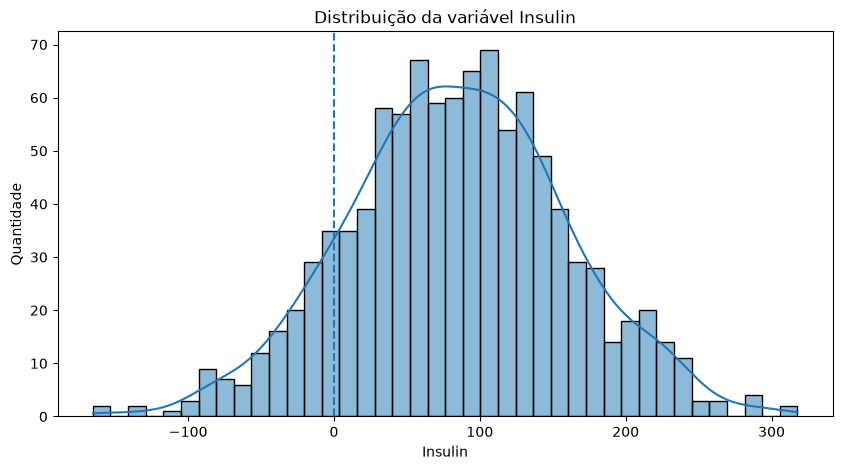

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Insulin",
    bins=40,
    kde=True
)

plt.axvline(0, linestyle="--")

plt.title("Distribuição da variável Insulin")
plt.xlabel("Insulin")
plt.ylabel("Quantidade")

plt.show()

In [45]:
print(
    df.groupby("Diagnosis")["Insulin"]
      .agg(["count", "mean", "median", "min", "max"])
)

           count       mean     median         min         max
Diagnosis                                                     
0            694  82.823035  83.111679 -165.310033  293.032572
1            306  88.573505  88.250515 -129.137490  317.701852
